# Q2 · Notebook 2 — Baseline: BiGRU + additive attention pooling

**Architecture:** Embedding (300-d fastText, **frozen in epoch 1, trainable afterwards**) →
2-layer bidirectional GRU (256 units per direction, packed sequences so padding is ignored)
→ additive attention pooling (`e_t = vᵀ tanh(W h_t + b)`, softmax over real tokens,
`c = Σ α_t h_t`) → Dropout(0.5) → Linear(512 → 5).

**Training:** cross-entropy, Adam (lr 1e-3), gradient clipping (max norm 1.0), batch 128,
up to 10 epochs, **early stopping on validation macro-F1** (patience 2), best checkpoint
restored before the single test evaluation. Two seeds (42, 13).

In [1]:
# --- Setup: work from the project root (the folder that contains src/) ---------------
# Colab: upload q2_rating_prediction.zip, then run
#   !unzip -q q2_rating_prediction.zip -d /content && %cd /content/q2_rating_prediction
# (or keep it on Google Drive so outputs survive a disconnect - see README).
import os, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
print("project root:", ROOT)

import json
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from IPython.display import Image, Markdown, display
pd.set_option("display.max_colwidth", 160)
print("torch", torch.__version__, "| GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")

project root: /content/q2_rating_prediction


torch 2.11.0+cu130 | GPU: Tesla T4


In [2]:
from src.train_baseline import BaselineConfig, run_baseline
from src.models import BiGRUAttentionClassifier
from src.utils import count_parameters

SEEDS = [42, 13]
BASE = dict(embeddings="fasttext", batch_size=128, lr=1e-3, clip_norm=1.0,
            max_epochs=10, patience=2, freeze_epochs=1)

m = BiGRUAttentionClassifier(np.load("data/classic/embedding_matrix.npy"))
print(m)
m.set_embedding_trainable(True)
print(f"parameters: {count_parameters(m):,} (of which embeddings {m.embedding.weight.numel():,})")
del m

BiGRUAttentionClassifier(
  (embedding): Embedding(26126, 300, padding_idx=0)
  (emb_dropout): Dropout(p=0.25, inplace=False)
  (gru): GRU(300, 256, num_layers=2, batch_first=True, dropout=0.3, bidirectional=True)
  (attention): AdditiveAttentionPooling(
    (proj): Linear(in_features=512, out_features=256, bias=True)
    (v): Linear(in_features=256, out_features=1, bias=False)
  )
  (dropout): Dropout(p=0.5, inplace=False)
  (fc): Linear(in_features=512, out_features=5, bias=True)
)
parameters: 10,011,757 (of which embeddings 7,837,800)


## Train (one run per seed)

Each run writes `outputs/bigru_attn_seed<S>/` with `config.json`, `train.log`,
`history.json` (curves), `best.pt`, `metrics.json` and validation/test predictions.
Finished runs are skipped automatically, so it is safe to re-run this cell after a
disconnect.

In [3]:
baseline_metrics = {}
for seed in SEEDS:
    baseline_metrics[seed] = run_baseline(BaselineConfig(seed=seed, **BASE))

[09:29:50] device=cuda amp=torch.float16 run=bigru_attn_seed42


[09:29:58] train=200,000 val=5,000 test=5,000 | vocab=26,126


[09:29:58] epoch 1: embeddings FROZEN


epoch 1:   0%|          | 0/1563 [00:00<?, ?it/s]

[09:30:25] epoch 1.00 | train loss 0.9993 F1 0.5596 | val loss 0.8957 F1 0.6080 acc 0.6082 MAE 0.4572 | *best*


[09:30:25] epoch 2: embeddings TRAINABLE


... (20 outputs left out)

epoch 5:   0%|          | 0/1563 [00:00<?, ?it/s]

[09:34:31] epoch 5.00 | train loss 0.6400 F1 0.7313 | val loss 0.9674 F1 0.6097 acc 0.6080 MAE 0.4576 | no gain 2/2


[09:34:31] early stopping: no val macro-F1 gain for 2 evaluations


[09:34:33] TEST  acc 0.6350 | macro-F1 0.6340 | MAE 0.4264  -> outputs/bigru_attn_seed13


## Results

In [4]:
from src.analysis import load_runs, main_table, per_class_table, ordinal_table, plot_curves, plot_confusions, BASELINE
from src.metrics import STAR_NAMES
Path("results").mkdir(exist_ok=True)
groups = {BASELINE: load_runs("outputs")[BASELINE]}

per_seed = pd.DataFrame([{ "seed": r["seed"], "test acc": r["metrics"]["test"]["accuracy"],
                           "test macro-F1": r["metrics"]["test"]["macro_f1"], "test MAE": r["metrics"]["test"]["mae"],
                           "best val macro-F1": r["metrics"]["val"]["macro_f1"],
                           "best epoch": r["metrics"]["best_eval"]["epoch"], "minutes": r["metrics"]["train_time_min"]}
                         for r in groups[BASELINE]])
display(per_seed.round(4))
display(main_table(groups))
display(per_class_table(groups))
display(ordinal_table(groups))

,seed,test acc,test macro-F1,test MAE,best val macro-F1,best epoch,minutes
0,13,0.6350,0.6340,0.4264,0.6357,3.0,2.50
1,42,0.6394,0.6391,0.4258,0.6326,2.0,2.01


,Model,Seeds,Test accuracy (%),Test macro-F1 (%),Test MAE (stars),Val macro-F1 (%),Trainable params (M),Train time / seed (min),Best val epoch
0,BiGRU + attention,"13, 42",63.72 ± 0.31,63.65 ± 0.36,0.426 ± 0.000,63.42 ± 0.22,10.0,2.3,"3.00, 2.00"


,Model,F1 1 star (%),F1 2 stars (%),F1 3 stars (%),F1 4 stars (%),F1 5 stars (%)
0,BiGRU + attention,71.01 ± 0.25,54.67 ± 0.01,54.74 ± 1.17,60.01 ± 0.43,77.83 ± 0.06


,Model,Exact (%),Off by 1 star (%),Off by >=2 stars (%),Errors that are adjacent (%),4<->5 confusion rate (%),1<->5 confusions (count / 5000),MAE (stars)
0,BiGRU + attention,63.72 ± 0.31,30.95 ± 0.61,5.33 ± 0.30,85.30 ± 0.94,19.38 ± 0.18,10.0 ± 0.0,0.426 ± 0.000


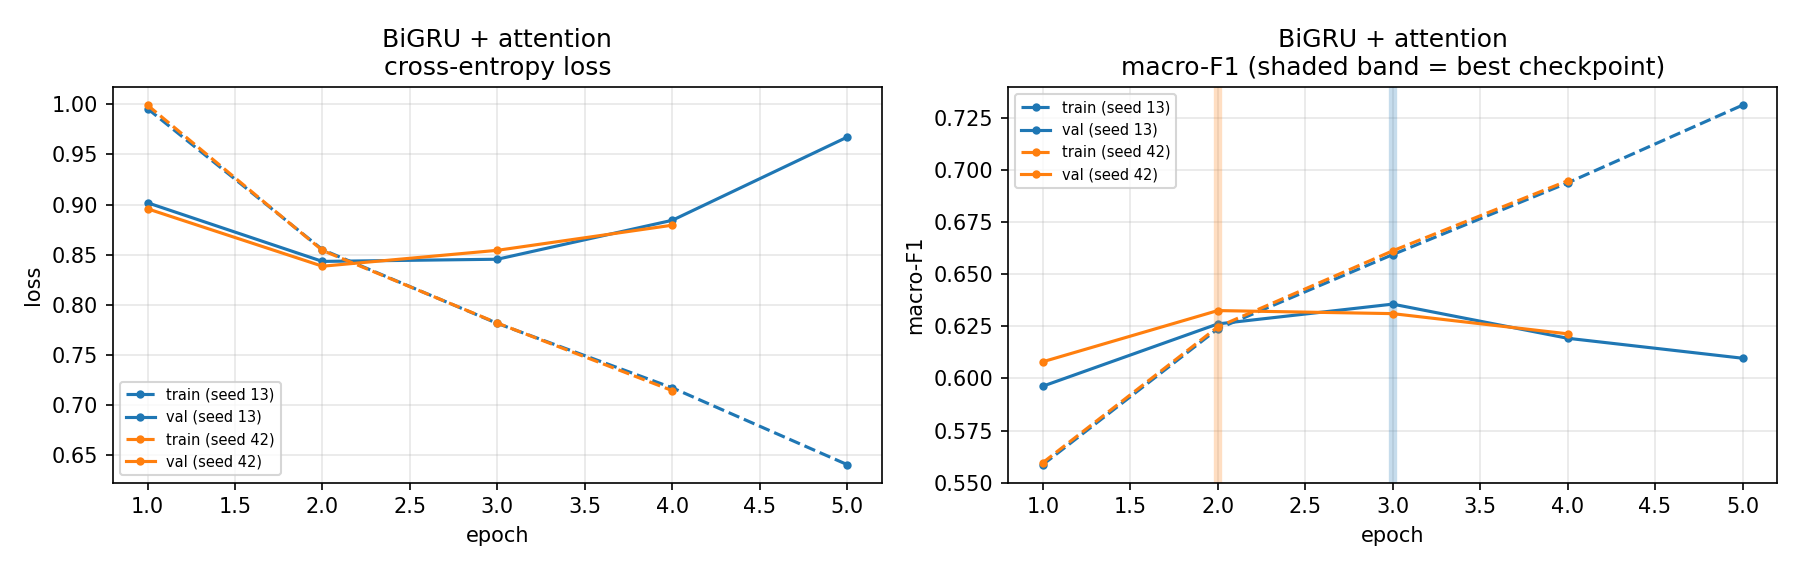

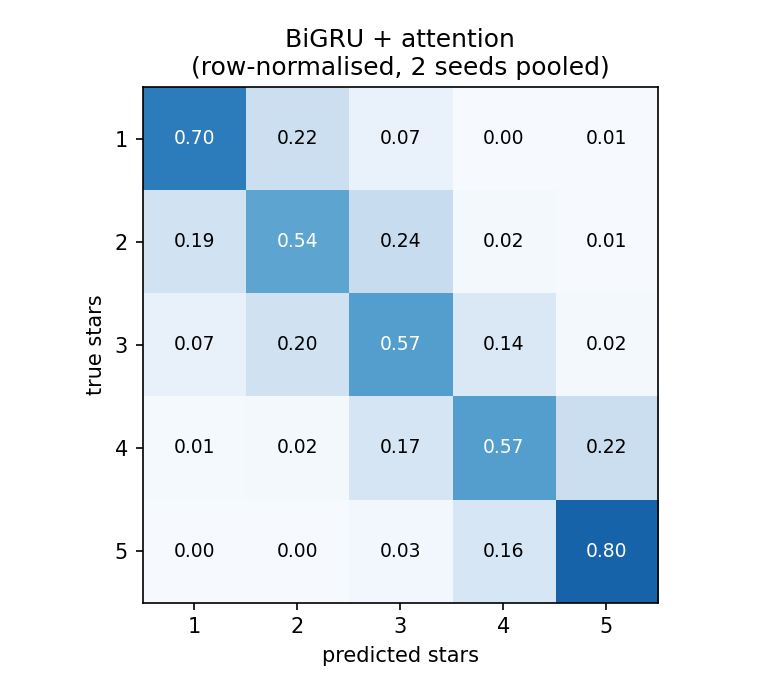

In [5]:
for p in plot_curves(groups, "results")[1:]:
    display(Image(str(p)))
display(Image(str(plot_confusions(groups, [BASELINE], "results/confusion_baseline.png"))))

## What does the attention pooling look at?

The attention weights α_t come straight from the model's pooling layer. Words shown as
`[UNK]` are outside the vocabulary (min. frequency 3).

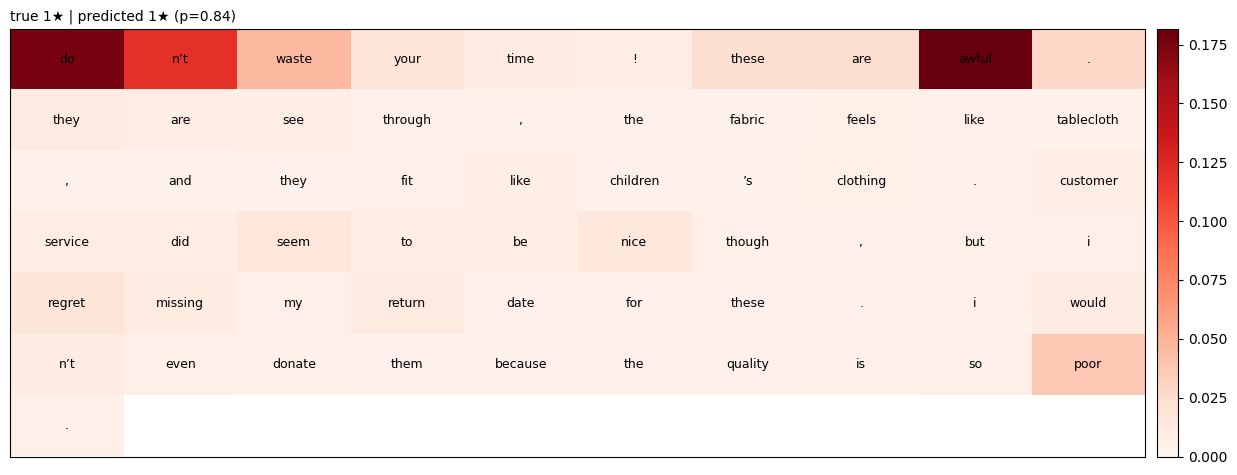

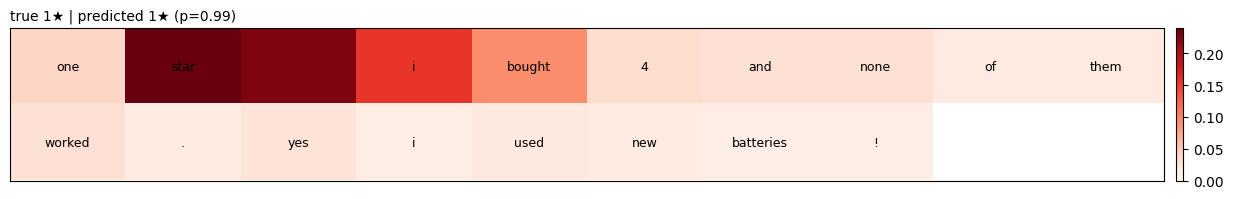

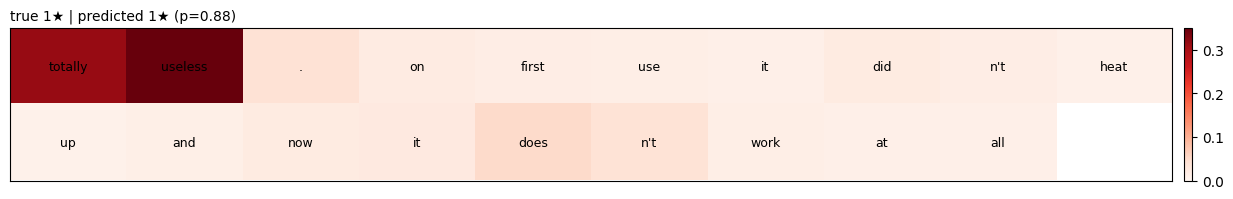

In [6]:
from src.data import load_reviews
from src.explain import load_bigru, bigru_attention, plot_word_heatmap
model, stoi, cfg = load_bigru(f"outputs/bigru_attn_seed{SEEDS[0]}", "data")
test = load_reviews("data")[0]["test"]
for i in [0, 1, 2]:
    text, label = test[i]["text"], test[i]["label"]
    out = bigru_attention(model, stoi, cfg, text)
    fig = plot_word_heatmap(out["words"], out["attention"],
                            f"true {label + 1}★ | predicted {out['pred'] + 1}★ (p={out['probs'].max():.2f})")
    plt.show()